In [1]:
import pandas as pd

In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
caminho = "https://www-usr.inf.ufsm.br/~joaquim/UFSM/DM/ds/AgeOfMythology_work.csv"
df = pd.read_csv(caminho, dtype="string", keep_default_na=False, encoding="utf-8")

In [3]:
df

,Unit,Age,Cost,Pop,DmgHack,DmgPierce,DmgCrush,Range,HP,ArmorHack,ArmorPierce,ArmorCrush,Speed,LOS,Train time,Bonus,Other,Class
0,Pegasus,1,50F 2Fv,2,--,--,--,0,140,50,50,99,5,18,6,,,Myth Unit
1,Centaur,2,200W 15Fv,3,--,12,--,12,220,25,35,80,5,20,19,"Myth units, -Heroes",,Myth Unit
2,Cyclops,2,250F 22Fv,4,15,--,12,2,600,40,50,80,3.2,16,20,Myth units,,Myth Unit
3,Minotaur,2,200F 16Fv,4,15,--,10,2,300,60,50,80,4,20,20,Myth units,,Myth Unit
4,Hydra,3,250F 28Fv,5,20,--,10,3,800,60,40,80,4,16,20,"Myth units, -Heroes",,Myth Unit
5,Manticore,3,300W 28Fv,5,--,11**,--,16,420,30,60,80,4.3,20,17,"Myth units, -Heroes",,Myth Unit
6,Nemean Lion,3,200G 25Fv,4,20,--,10,1,660,30,60,80,4.8,16,20,"Myth units, -Heroes",,Myth Unit
7,Colossus,4,300G 40Fv,5,20,--,50,3,1100_,50,80,80,2.4,16,24,"Myth units, -Heroes",,Myth Unit
8,Chimera,4,300G 30Fv,4,20,--,--,1,800,60,60,80,5.3,16,20,"Myth units, -Heroes",,Myth Unit
9,Medusa,4,250G 40Fv,5,--,15,12.5,10,360,60,70,80,4.3,18,20,"Myth units, -Heroes",,Myth Unit


In [4]:

import pandas as pd

RECURSOS = {
    "F": "cost_food",
    "W": "cost_wood",
    "G": "cost_gold",
    "Fv": "cost_favor",
}

COLUNAS_NUMERICAS = [
    "age", "pop", "dmg_hack", "dmg_pierce", "dmg_crush",
    "range", "hp", "armor_hack", "armor_pierce",
    "armor_crush", "speed", "los", "train_time",
]


def extrair_custos(valor):
    if pd.isna(valor) or valor in ("", "--"):
        return {nome: 0 for nome in RECURSOS.values()}

    custos = {nome: 0 for nome in RECURSOS.values()}

    for item in valor.replace(",", " ").split():
        recurso = next(
            (r for r in RECURSOS if item.endswith(r)),
            None
        )

        if recurso is None:
            raise ValueError(f"Custo inválido: {item}")

        quantidade = item.removesuffix(recurso)

        if not quantidade.isdigit():
            raise ValueError(f"Custo inválido: {item}")

        custos[RECURSOS[recurso]] += int(quantidade)

    return custos


def limpar_dataset(df) -> pd.DataFrame:
    df = df.copy()

    # Padroniza espaços e valores ausentes
    df.columns = [
        " ".join(col.replace("\u00a0", " ").split())
        for col in df.columns
    ]

    for coluna in df.columns:
        df[coluna] = df[coluna].map(
            lambda x: " ".join(x.replace("\u00a0", " ").split())
            if isinstance(x, str) else x
        )
    
    df = df.replace("", pd.NA)

    # Renomeia colunas
    df = df.rename(columns={
        "Unit": "unit",
        "Age": "age",
        "Cost": "cost_raw",
        "Pop": "pop",
        "DmgHack": "dmg_hack",
        "DmgPierce": "dmg_pierce",
        "DmgCrush": "dmg_crush",
        "Range": "range",
        "HP": "hp",
        "ArmorHack": "armor_hack",
        "ArmorPierce": "armor_pierce",
        "ArmorCrush": "armor_crush",
        "Speed": "speed",
        "LOS": "los",
        "Train time": "train_time",
        "Bonus": "bonus",
        "Other": "other",
        "Class": "unit_class",
    })

    # Corrige erros de escrita
    for coluna in ["unit_class", "bonus"]:
        df[coluna] = df[coluna].str.replace(
            "Infantary", "Infantry", regex=False
        )

    # Extrai custos
    custos = df["cost_raw"].apply(extrair_custos)
    custos = pd.DataFrame(custos.tolist(), index=df.index)

    for coluna in custos.columns:
        df[coluna] = custos[coluna].astype("Int64")

    # Remove marcações dos danos
    for coluna in ["dmg_hack", "dmg_pierce", "dmg_crush"]:
        df[coluna] = df[coluna].str.replace("*", "", regex=False)

    # Corrige HP
    df["hp"] = df["hp"].str.removesuffix("_")

    # Remove símbolo de porcentagem das armaduras
    for coluna in ["armor_hack", "armor_pierce", "armor_crush"]:
        df[coluna] = df[coluna].str.removesuffix("%")

    colunas_dmg = ["dmg_hack", "dmg_pierce", "dmg_crush"]

    df["does_attack"] = df[colunas_dmg].ne("--").any(axis=1).astype(int)


    # Converte colunas numéricas
    for coluna in COLUNAS_NUMERICAS:

        substituicoes = {
            "--": 0 if coluna.startswith("dmg_") else pd.NA,
            "none": pd.NA,
        }

        df[coluna] = pd.to_numeric(
            df[coluna].replace(substituicoes),
            errors="raise"
        )

    # Define tipos
    colunas_inteiras = [
        "age", "pop", "range", "hp",
        "armor_hack", "armor_pierce", "armor_crush",
        "los", "train_time",
    ]

    colunas_decimais = [
        "dmg_hack", "dmg_pierce", "dmg_crush", "speed",
    ]

    df[colunas_inteiras] = df[colunas_inteiras].astype("Int64")
    df[colunas_decimais] = df[colunas_decimais].astype("Float64")

    # Remove duplicatas
    df = df.drop_duplicates().reset_index(drop=True)

    # Valida valores
    for coluna in ["armor_hack", "armor_pierce", "armor_crush"]:
        if (df[coluna].dropna() > 100).any():
            raise ValueError(f"Armadura inválida: {coluna}")

    # Organiza colunas
    ordem = [
        "unit", "unit_class", "age",
        "cost_food", "cost_wood", "cost_gold", "cost_favor",
        "pop", "hp",
        "dmg_hack", "dmg_pierce", "dmg_crush",
        "armor_hack", "armor_pierce", "armor_crush",
        "range", "speed", "los", "train_time",
        "bonus", "other",
    ]

    return df[ordem]


In [5]:
df_limpo = limpar_dataset(df)

In [6]:
display(df_limpo)

,unit,unit_class,age,cost_food,cost_wood,cost_gold,cost_favor,pop,hp,dmg_hack,dmg_pierce,dmg_crush,armor_hack,armor_pierce,armor_crush,range,speed,los,train_time,bonus,other
0,Pegasus,Myth Unit,1,50,0,0,2,2,140,0.0,0.0,0.0,50,50,99,0,5.0,18,6,NaN,NaN
1,Centaur,Myth Unit,2,0,200,0,15,3,220,0.0,12.0,0.0,25,35,80,12,5.0,20,19,"Myth units, -Heroes",NaN
2,Cyclops,Myth Unit,2,250,0,0,22,4,600,15.0,0.0,12.0,40,50,80,2,3.2,16,20,Myth units,NaN
3,Minotaur,Myth Unit,2,200,0,0,16,4,300,15.0,0.0,10.0,60,50,80,2,4.0,20,20,Myth units,NaN
4,Hydra,Myth Unit,3,250,0,0,28,5,800,20.0,0.0,10.0,60,40,80,3,4.0,16,20,"Myth units, -Heroes",NaN
5,Manticore,Myth Unit,3,0,300,0,28,5,420,0.0,11.0,0.0,30,60,80,16,4.3,20,17,"Myth units, -Heroes",NaN
6,Nemean Lion,Myth Unit,3,0,0,200,25,4,660,20.0,0.0,10.0,30,60,80,1,4.8,16,20,"Myth units, -Heroes",NaN
7,Colossus,Myth Unit,4,0,0,300,40,5,1100,20.0,0.0,50.0,50,80,80,3,2.4,16,24,"Myth units, -Heroes",NaN
8,Chimera,Myth Unit,4,0,0,300,30,4,800,20.0,0.0,0.0,60,60,80,1,5.3,16,20,"Myth units, -Heroes",NaN
9,Medusa,Myth Unit,4,0,0,250,40,5,360,0.0,15.0,12.5,60,70,80,10,4.3,18,20,"Myth units, -Heroes",NaN


Descobrir quantos dados tem de cada classe e quais coluna tem valor ausente

In [7]:
print(df_limpo.isna().sum()[lambda s: s > 0])   #colunas com valores ausentes
df_limpo["unit_class"].value_counts()

age            2
pop            1
range          1
train_time     3
bonus         17
other         73
dtype: int64


unit_class
Myth Unit          30
Hero               18
Animal              7
Siege               6
Cavalry             6
Melee Infantry      5
Ship                5
Ranged Infantry     4
Spear Infantry      1
Ranged Cavalry      1
Name: count, dtype: int64

Carregar o conjunto sem classe e escolher atributos

In [8]:
caminho_noClass = "https://www-usr.inf.ufsm.br/~joaquim/UFSM/DM/ds/AgeOfMythology_noClass.csv"
teste = pd.read_csv(caminho_noClass, encoding="utf-8-sig")

In [9]:
teste

,Age,Pop,DmgHack,DmgPierce,DmgCrush,Range,HP,ArmorHack,ArmorPierce,ArmorCrush,Speed,Train time,Favor
0,3,5,12,0,0,1,800,60,60,80,3.60,19,15
1,2,1,5,0,0,1,50,10,5,99,3.00,20,5
2,2,3,11,5,0,1,400,30,50,99,3.80,17,5
3,3,2,0,6,0,20,60,15,15,99,3.75,12,0
4,3,3,8,0,0,1,120,10,35,99,4.00,15,0
5,3,2,8,4,0,1,95,15,10,99,3.50,14,0
6,4,3,10,0,30,16,180,30,70,50,2.50,21,0
7,4,3,11,10,0,1,140,15,40,99,3.50,22,0
8,2,3,10,0,8,1,175,50,25,80,4.00,26,10
9,4,5,20,0,0,1,360,60,69,80,4.10,30,25


In [10]:
# padronizar 
mapa = {
    "Age": "age", "Pop": "pop",
    "DmgHack": "dmg_hack", "DmgPierce": "dmg_pierce", "DmgCrush": "dmg_crush",
    "Range": "range", "HP": "hp",
    "ArmorHack": "armor_hack", "ArmorPierce": "armor_pierce", "ArmorCrush": "armor_crush",
    "Speed": "speed", "Train time": "train_time", "Favor": "cost_favor",
}
teste = teste.rename(columns=mapa)

ATRIBUTOS = list(mapa.values())
#deixar apenas os atributo que tem no sem classe
treino = df_limpo[["unit_class"] + ATRIBUTOS].copy()
treino.head()

,unit_class,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor
0,Myth Unit,1,2,0.0,0.0,0.0,0,140,50,50,99,5.0,6,2
1,Myth Unit,2,3,0.0,12.0,0.0,12,220,25,35,80,5.0,19,15
2,Myth Unit,2,4,15.0,0.0,12.0,2,600,40,50,80,3.2,20,22
3,Myth Unit,2,4,15.0,0.0,10.0,2,300,60,50,80,4.0,20,16
4,Myth Unit,3,5,20.0,0.0,10.0,3,800,60,40,80,4.0,20,28


Ajustar o valores ausentes para treino 

In [11]:
treino[ATRIBUTOS] = treino[ATRIBUTOS].fillna(0).astype(float)

teste = teste[ATRIBUTOS].astype(float)

X = treino[ATRIBUTOS] #perunta
y = treino["unit_class"]

Teste de  diferença entre os dados, faz a média do valores de cada atributo por classe

In [12]:
treino.groupby("unit_class")[["age", "pop", "dmg_hack", "dmg_pierce", "dmg_crush", "range", "hp",
       "armor_hack", "armor_pierce", "armor_crush", "speed", "train_time",
       "cost_favor"]].mean().round(1)

,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor
unit_class,,,,,,,,,,,,,
Animal,2.7,2.1,8.7,0.0,0.0,0.9,77.1,25.0,20.7,99.0,4.2,20.1,8.1
Cavalry,3.0,2.7,9.2,0.0,0.0,1.0,193.3,21.7,37.5,99.0,5.0,11.8,0.0
Hero,2.1,2.4,9.7,2.6,0.3,5.8,302.0,25.8,31.1,94.6,4.5,15.4,2.4
Melee Infantry,2.2,1.6,8.0,0.0,0.0,1.0,92.0,35.0,23.0,99.0,4.5,8.6,0.0
Myth Unit,2.9,4.1,11.8,5.6,8.4,5.5,519.3,44.8,53.2,80.6,4.3,17.6,22.9
Ranged Cavalry,3.0,3.0,0.0,8.5,0.0,20.0,90.0,30.0,20.0,99.0,5.0,6.0,0.0
Ranged Infantry,2.8,2.2,1.1,3.5,1.5,16.2,65.0,18.8,16.2,99.0,4.0,13.2,0.0
Ship,2.2,2.0,4.0,1.2,1.2,6.4,262.0,32.0,44.0,21.0,5.6,15.2,0.0
Siege,3.5,3.3,0.0,5.3,28.7,18.2,245.8,15.8,91.8,81.7,2.7,20.0,0.0


Separar o dataset e criar a árvore
Divide o dataset em 70% / 30%

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
# Devolve:  atributos de treino, atributos de teste,
# classes de treino, classes de teste.

#cria a árvore vazia, com o critério de divisão de entropia
arvore = DecisionTreeClassifier(criterion="entropy", random_state=42)
# fit = treinar
arvore.fit(X_train, y_train)
print("Profundidade:", arvore.get_depth(), "| Folhas:", arvore.get_n_leaves())


Profundidade: 7 | Folhas: 15


DecisionTreeClassifier implementa o CART

visualizar a árvore e as regras

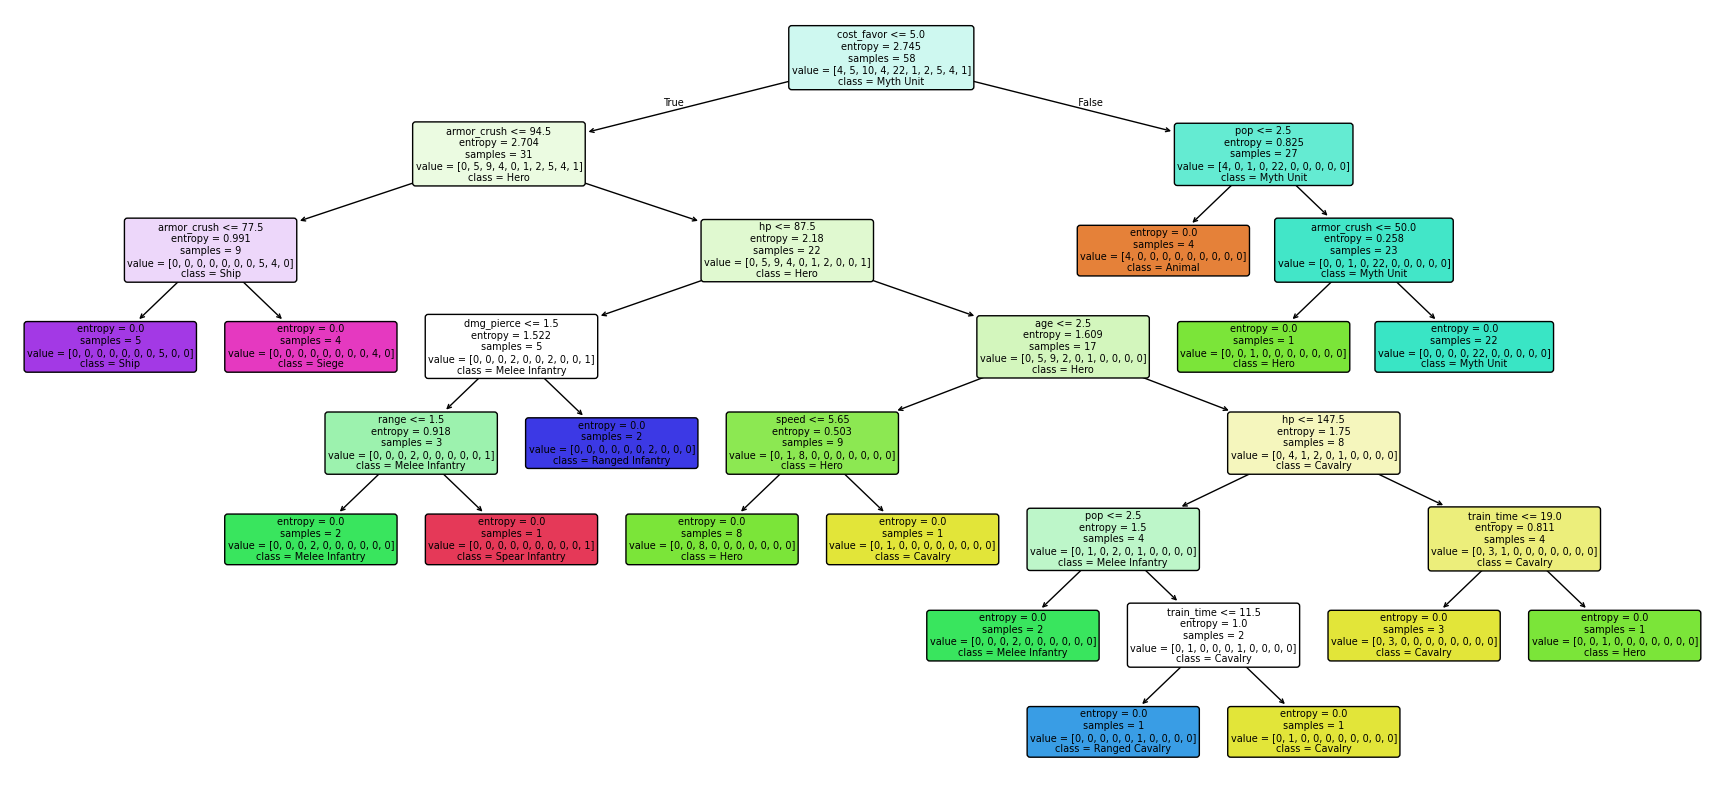

In [18]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(arvore, feature_names=ATRIBUTOS, class_names=arvore.classes_,
          filled=True, rounded=True, fontsize=7, ax=ax)
plt.show()



avaliar no conjunto de teste

Acurácia: 0.6


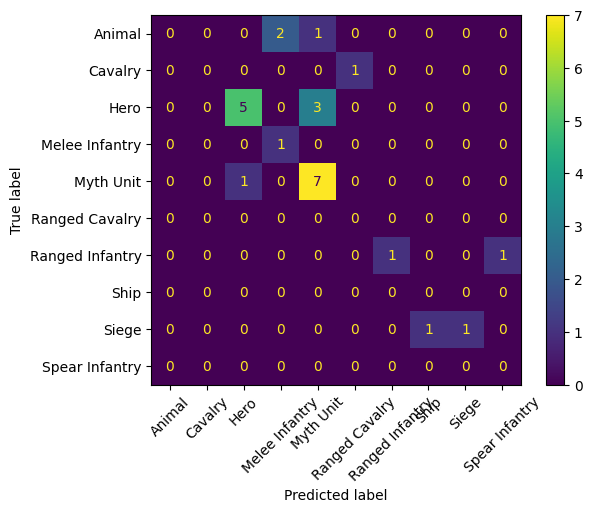

In [20]:
y_pred = arvore.predict(X_test) #testar

print("Acurácia:", round(accuracy_score(y_test, y_pred), 3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=45)
plt.show()

Poda da arvore

boosting